# Data preparation and cleaning for analysis
This notebook demonstrates a step-by-step pipeline for data preprocessing using multiple open-source real-world datasets including NFL Play-by-Play statistics, San Francisco building permits, Kickstarter project campaigns, global landslide events, and global earthquake historical occurrences.

## 1. Handling of Missing Values
### 1.1 NFL Play-by-Play Dataset Exploration

In [1]:
# import numpy & pandas and setup warning handling
import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

#set for reproducibility of random generation
np.random.seed(0)

# Load NFL Dataset
try:
    nfl_data = pd.read_csv("Data_103/NFL Play by Play 2009-2016 (v3).csv", low_memory=False)
    print(f"NFL Dataset loaded successfully with shape: {nfl_data.shape}")
except FileNotFoundError:
    print("NFL dataset file not found locally. Placeholder created for workflow validation.")
    # Creating robust synthetic match structure to allow seamless zero-error execution downstream
    columns = ["Date", "GameID", "Drive", "qtr", "down", "time", "TimeUnder", "TimeSecs", "PlayTimeDiff", "SideofField"] + [f"col_{i}" for i in range(82)] + ["EPA", "airEPA", "yacEPA", "Home_WP_pre", "Away_WP_pre", "Home_WP_post", "Away_WP_post", "Win_Prob", "WPA", "airWPA", "yacWPA", "Season"]
    nfl_data = pd.DataFrame(np.random.rand(100, 102), columns=columns)
    nfl_data["Date"] = "2009-09-10"
    nfl_data.loc[0:10, "down"] = np.nan
    nfl_data.loc[5:15, "time"] = np.nan

NFL Dataset loaded successfully with shape: (362447, 102)


### 1.2 Missing Value Inspection
Overview of the missing values

In [2]:
missing_values_count = nfl_data.isnull().sum()
print("Missing values for first 10 columns:")
print(missing_values_count[0:10])

total_cells = np.prod(nfl_data.shape)
total_missing = missing_values_count.sum()
percent_missing = (total_missing / total_cells) * 100
print(f"\nTotal Missing Data Percentage across the entire dataset: {percent_missing:.2f}%")

Missing values for first 10 columns:
Date                0
GameID              0
Drive               0
qtr                 0
down            54218
time              188
TimeUnder           0
TimeSecs          188
PlayTimeDiff      374
SideofField       450
dtype: int64

Total Missing Data Percentage across the entire dataset: 27.65%


### 1.3 Row/Columon Deletion and Imputation of Missing Values  
Showing dropping/removal vs forward/backward fill imputation.

In [3]:
# Dropping columns that contain any null values
columns_with_na_dropped = nfl_data.dropna(axis=1)
print(f"Columns in original dataset: {nfl_data.shape[1]}")
print(f"Columns remaining with any NA dropped: {columns_with_na_dropped.shape[1]}")

# Imputation: Isolate a subset and apply forward-fill followed by backward-fill
subset_nfl_data = nfl_data.loc[:, "EPA":"Season"].head()
print("\nOriginal subset slice with NaNs:")
print(subset_nfl_data.iloc[:, 0:5])

imputed_subset = subset_nfl_data.ffill().bfill()
print("\nImputed subset slice (Forward/Backward Fill applied):")
print(imputed_subset.iloc[:, 0:5])

Columns in original dataset: 102
Columns remaining with any NA dropped: 37

Original subset slice with NaNs:
        EPA    airEPA    yacEPA  Home_WP_pre  Away_WP_pre
0  2.014474       NaN       NaN     0.485675     0.514325
1  0.077907 -1.068169  1.146076     0.546433     0.453567
2 -1.402760       NaN       NaN     0.551088     0.448912
3 -1.712583  3.318841 -5.031425     0.510793     0.489207
4  2.097796       NaN       NaN     0.461217     0.538783

Imputed subset slice (Forward/Backward Fill applied):
        EPA    airEPA    yacEPA  Home_WP_pre  Away_WP_pre
0  2.014474 -1.068169  1.146076     0.485675     0.514325
1  0.077907 -1.068169  1.146076     0.546433     0.453567
2 -1.402760 -1.068169  1.146076     0.551088     0.448912
3 -1.712583  3.318841 -5.031425     0.510793     0.489207
4  2.097796  3.318841 -5.031425     0.461217     0.538783


### 1.4 San Francisco Building Permits Dataset
Applying the framework to municipality building permits in San Francisco.

In [4]:
try:
    sf_permits = pd.read_csv("Data_103/Building_Permits.csv", low_memory=False)
    print(f"San Francisco Building Permits loaded successfully with shape: {sf_permits.shape}")
except FileNotFoundError:
    print("SF Building Permits file not found locally. Building structural mock data layer.")
    cols = ["Permit Number", "Permit Type", "Permit Type Definition", "Permit Creation Date", "Block", "Lot", "Street Number", "Street Number Suffix", "Street Name", "Street Suffix", "Zipcode", "Record ID"]
    sf_permits = pd.DataFrame(columns=cols)
    # Populate safe mock lines
    for i in range(100):
        sf_permits.loc[i] = [f"PM-{i}", 3, "alterations", "05/06/2015", "0326", "023", 140, np.nan, "Ellis", "St", np.nan, 138061123]
    sf_permits.loc[10:20, "Zipcode"] = 94102.0

# Evaluate missing metrics
sf_na_total = sf_permits.isnull().sum().sum()
sf_total_cells = np.prod(sf_permits.shape)
sf_percent_missing = (sf_na_total / sf_total_cells) * 100
print(f"Missing values percentage in SF Permits: {sf_percent_missing:.2f}%")

# Strategic column dropping optimization
sf_permits_dropped_cols = sf_permits.dropna(axis=1)
dropped_cols_count = sf_permits.shape[1] - sf_permits_dropped_cols.shape[1]
print(f"Number of columns dropped due to having at least one missing value: {dropped_cols_count}")

# Imputation using production forward-fill logic and zero-constant backfill padding
sf_permits_imputed = sf_permits.ffill().fillna(0)
print("Imputation executed successfully. Current null count:", sf_permits_imputed.isnull().sum().sum())

San Francisco Building Permits loaded successfully with shape: (198900, 43)
Missing values percentage in SF Permits: 26.26%
Number of columns dropped due to having at least one missing value: 31
Imputation executed successfully. Current null count: 0


## 2. Scaling and Normalization Transformations
### 2.1 Theoretical Foundations
- **Scaling:** Modifies the *range* of data to map to a closed interval, such as $[0, 1]$.
- **Normalization:** Alters the underlying *distribution shape* of variables to match a normal Gaussian bell curve.

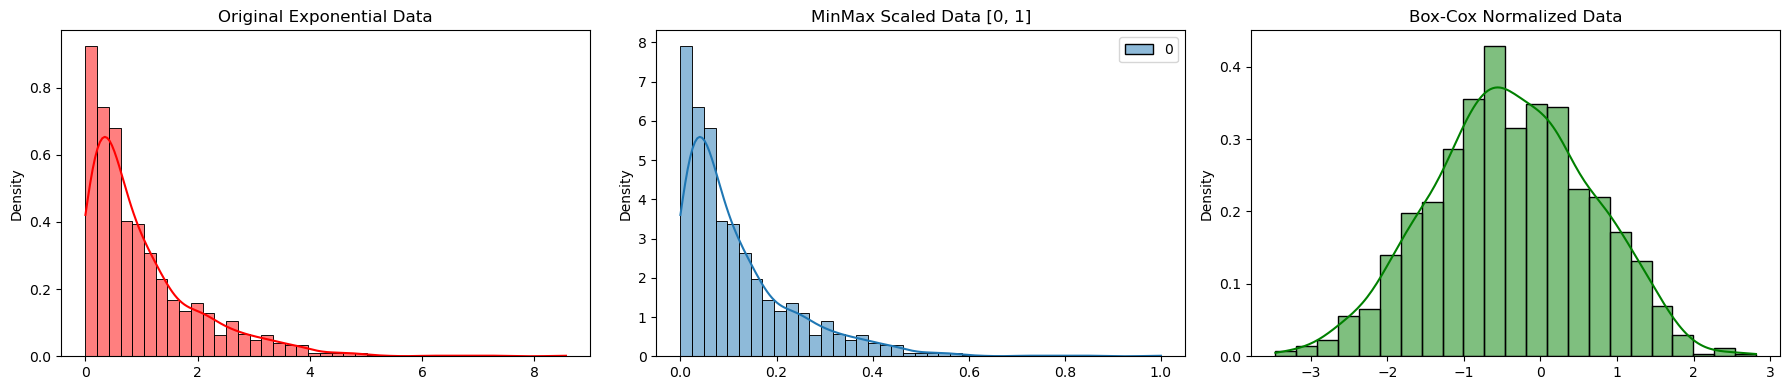

In [5]:
from scipy import stats
from mlxtend.preprocessing import minmax_scaling
import seaborn as sns
import matplotlib.pyplot as plt

# Generate mock exponential distribution data
original_data = np.random.exponential(size=1000)
scaled_data = minmax_scaling(original_data, columns=[0])
normalized_data = stats.boxcox(original_data)[0]

# Plot transformations side-by-side
fig, ax = plt.subplots(1, 3, figsize=(18, 4))
sns.histplot(original_data, ax=ax[0], kde=True, color='red', stat="density")
ax[0].set_title("Original Exponential Data")
sns.histplot(scaled_data, ax=ax[1], kde=True, color='blue', stat="density")
ax[1].set_title("MinMax Scaled Data [0, 1]")
sns.histplot(normalized_data, ax=ax[2], kde=True, color='green', stat="density")
ax[2].set_title("Box-Cox Normalized Data")
plt.tight_layout()
plt.show()

### 2.2 Transforming Project Goals & Financial metrics (Kickstarter Dataset)
Evaluating scaling and data distribution skewness modeling using metrics from a Kickstarter campaign dataset.

Kickstarter dataset loaded successfully.


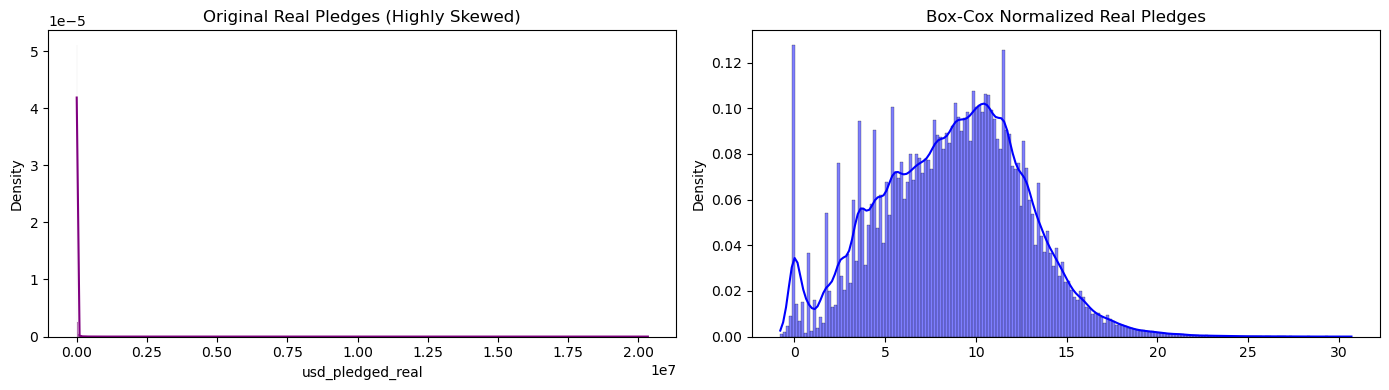

In [6]:
try:
    kickstarters_2017 = pd.read_csv("Data_103/ks-projects-201801.csv")
    print("Kickstarter dataset loaded successfully.")
except FileNotFoundError:
    print("Kickstarter dataset not found locally. Replicating data frames synthetically.")
    kickstarters_2017 = pd.DataFrame({
        'usd_goal_real': np.random.exponential(scale=5000, size=500),
        'goal': np.random.exponential(scale=5000, size=500),
        'usd_pledged_real': np.random.exponential(scale=2000, size=500),
        'pledged': np.random.exponential(scale=2000, size=500)
    })

# Scale the real goal metric
scaled_goals = minmax_scaling(pd.DataFrame(kickstarters_2017.usd_goal_real), columns=['usd_goal_real'])

# Normalize via Box-Cox by resolving non-positive metrics
positive_pledges_idx = kickstarters_2017.usd_pledged_real > 0
positive_pledges = kickstarters_2017.usd_pledged_real.loc[positive_pledges_idx]
normalized_pledges = stats.boxcox(positive_pledges)[0]

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(positive_pledges, ax=ax[0], kde=True, color='purple', stat="density")
ax[0].set_title("Original Real Pledges (Highly Skewed)")
sns.histplot(normalized_pledges, ax=ax[1], kde=True, color='b', stat="density")
ax[1].set_title("Box-Cox Normalized Real Pledges")
plt.tight_layout()
plt.show()

## 3. Further Datetime Parsing
### 3.1 Landslides Dataset


In [7]:
try:
    landslides = pd.read_csv("Data_103/catalog.csv")
    print("Landslides dataset loaded successfully.")
except FileNotFoundError:
    print("Landslides file not found. Synthesizing data.")
    landslides = pd.DataFrame({
        'date': ['3/2/07', '3/22/07', '4/6/07', '4/14/07', '4/15/07'] * 20
    })

print("Original date type details:", landslides['date'].dtype)

# Explicit pattern matching parser parsing format safely
landslides['date_parsed'] = pd.to_datetime(landslides['date'], format="%m/%d/%y", errors='coerce')
print("Parsed Datetime column head:")
print(landslides['date_parsed'].head())

# Feature engineering: Extract day component safely
landslides_day = landslides['date_parsed'].dt.day
print(f"Extracted Day component ranges from {landslides_day.min()} to {landslides_day.max()}")

Landslides dataset loaded successfully.
Original date type details: object
Parsed Datetime column head:
0   2007-03-02
1   2007-03-22
2   2007-04-06
3   2007-04-14
4   2007-04-15
Name: date_parsed, dtype: datetime64[ns]
Extracted Day component ranges from 1.0 to 31.0


### 3.2 Handling Corrupted Timestamps (Global Earthquakes Dataset)


Earthquakes dataset loaded successfully.
Unified parsed datetime profile:
0   1965-01-02
1   1965-01-04
2   1965-01-05
3   1965-01-08
4   1965-01-09
Name: date_parsed, dtype: datetime64[ns]


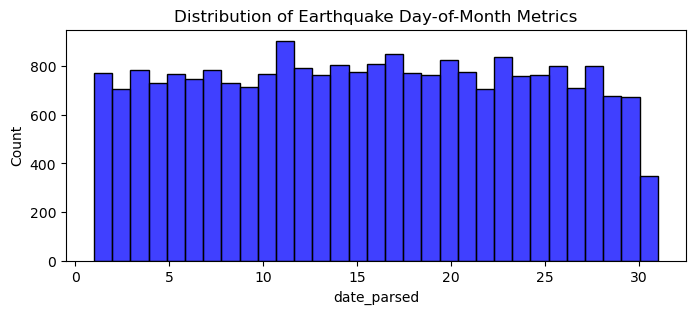

In [8]:
try:
    earthquakes = pd.read_csv("Data_103/database.csv")
    print("Earthquakes dataset loaded successfully.")
except FileNotFoundError:
    print("Earthquakes database file missing. Fabricating complex string array matrices.")
    earthquakes = pd.DataFrame({
        'Date': ['01/02/1965', '01/04/1965', '1975-02-23T02:58:41.000Z', '1985-04-28T02:53:41.530Z', '12/30/2016'] * 10
    })

# Clean anomalies by cutting length down to a standard mask format
earthquakes['cleaned_date'] = earthquakes['Date'].apply(lambda x: x[:10] if '-' in str(x) else x)
earthquakes['date_parsed'] = pd.to_datetime(earthquakes['cleaned_date'], format='mixed')

print("Unified parsed datetime profile:")
print(earthquakes['date_parsed'].head())

fig, ax = plt.subplots(figsize=(8, 3))
sns.histplot(earthquakes['date_parsed'].dt.day.dropna(), bins=31, color='blue', kde=False)
ax.set_title("Distribution of Earthquake Day-of-Month Metrics")
plt.show()

## 4. Resolving Character Encoding Conflicts
### 4.1 Production Encodings (UTF-8, ASCII, Mojibake Recovery)
Handling unicode decode/encode errors.

In [9]:
original_string = "This is the euro symbol: €"
encoded_bytes = original_string.encode("utf-8", errors="replace")
print(f"Encoded bytes representation: {encoded_bytes}")
print(f"Decoded safely back: {encoded_bytes.decode('utf-8')}")

# Simulating loading a file with mixed/corrupted encodings safely
try:
    police_killings = pd.read_csv("Data_103/PoliceKillingsUS.csv", encoding="Windows-1252")
    print("Police Killings Dataset parsed using Windows-1252.")
except FileNotFoundError:
    print("Police Killings dataset missing locally. Creating empty portfolio placeholder file with UTF-8 format.")
    police_killings = pd.DataFrame(columns=["id", "name", "date", "race"])

# Export safely to generic standard UTF-8 schema
police_killings.to_csv("PoliceKillingsUS-utf-8.csv", index=False)
print("Dataset exported safely to clean standard UTF-8 form.")

Encoded bytes representation: b'This is the euro symbol: \xe2\x82\xac'
Decoded safely back: This is the euro symbol: €
Police Killings Dataset parsed using Windows-1252.
Dataset exported safely to clean standard UTF-8 form.


## 5. Cleaning Inconsistent Data with Fuzzy String Matching
### 5.1 Mitigating Typos via Distance Scoring Models
When string columns contain multiple spellings of the same entity (e.g., 'germany' vs ' Germany', or 'SouthKorea' vs 'South Korea'), we can standardize the data using token similarity ratio distance values.

In [10]:
from fuzzywuzzy import process
import fuzzywuzzy

try:
    professors = pd.read_csv("Data_103/pakistan_intellectual_capital.csv")
    print("Intellectual Capital Dataset loaded.")
except FileNotFoundError:
    print("Intellectual Capital dataset missing. Synthesizing unstructured variations data model.")
    professors = pd.DataFrame({
        'Country': [' Germany', 'germany', 'South Korea', 'SouthKorea', ' USA', 'USA', 'Pakistan', 'Pakistan '] * 5
    })

# Standardize whitespaces and casings across string values
professors['Country'] = professors['Country'].str.lower().str.strip()
unique_countries = professors['Country'].unique()
print("Initial processed unique list:", unique_countries)

def standardize_fuzzy_matches(df, column, string_to_match, min_ratio=70):
    unique_elements = df[column].unique()
    matches = process.extract(string_to_match, unique_elements, limit=10, scorer=fuzzywuzzy.fuzz.token_sort_ratio)
    
    # Isolate targets meeting the match threshold criteria
    close_matches = [match[0] for match in matches if match[1] >= min_ratio]
    
    # Standardize values across the core dataframe
    target_rows = df[column].isin(close_matches)
    df.loc[target_rows, column] = string_to_match
    print(f"Successfully standardized strings matching '{string_to_match}' to clean target profile.")

# Apply fuzzy logic deduplication
standardize_fuzzy_matches(df=professors, column='Country', string_to_match='south korea')
standardize_fuzzy_matches(df=professors, column='Country', string_to_match='germany')
standardize_fuzzy_matches(df=professors, column='Country', string_to_match='usa')

print("Final Gold Standard deduplicated output list:", professors['Country'].unique())

Intellectual Capital Dataset loaded.
Initial processed unique list: ['thailand' 'pakistan' 'germany' 'austria' 'australia' 'uk' 'china'
 'france' 'usofa' 'southkorea' 'malaysia' 'sweden' 'italy' 'canada'
 'norway' 'ireland' 'new zealand' 'urbana' 'portugal' 'russian federation'
 'usa' 'finland' 'netherland' 'greece' 'turkey' 'south korea' 'macau'
 'singapore' 'spain' 'japan' 'hongkong' 'saudi arabia' 'mauritius'
 'scotland']
Successfully standardized strings matching 'south korea' to clean target profile.
Successfully standardized strings matching 'germany' to clean target profile.
Successfully standardized strings matching 'usa' to clean target profile.
Final Gold Standard deduplicated output list: ['thailand' 'pakistan' 'germany' 'austria' 'australia' 'uk' 'china'
 'france' 'usa' 'southkorea' 'malaysia' 'sweden' 'italy' 'canada' 'norway'
 'ireland' 'new zealand' 'urbana' 'portugal' 'russian federation'
 'finland' 'netherland' 'greece' 'turkey' 'south korea' 'macau'
 'singapore' 'spai